# HW2 Part 1: Cleaning and Validating `ohlc_hw`

**Goal:** turn the vendor's dirty daily OHLC table into a validated `ohlc_hw_cleaned` table that the report template (Part 2) and the batch script (Part 3) can trust.

The notebook follows the order the assignment asks for:

1. **Load and inspect** the raw table.
2. **Detect** issues (ticker markup, duplicates, missing values, missing trading days, invalid prices, OHLC bounds, zero volume, extreme returns, bad adjusted closes) and record them in a **Data Quality Report** *before* anything is repaired.
3. **Clean**, keeping a flag for every value that was changed and setting aside (quarantining) rows that cannot be repaired defensibly.
4. **Validate** the result, save it, and compare before/after statistics.

A small **injected example** at the end exercises the detectors and repairs that the real data happens not to need (missing raw prices, all-missing rows, `high < close`, missing volume, conflicting duplicate keys, a confirmed data error, a missing trading date).

**Run order:** run this notebook top to bottom (Restart & Run All) before running `02_stock_report_template.ipynb` or `03_run_all_stocks.py`.

## 0. Setup

All paths are relative to this homework folder:

- `data/data.db` is a **local working copy** of the course database. If it is missing, the next cell creates it by copying `Lectures/Lecture 4/data/data.db` (opened read-only). The course database itself is never written to.
- The raw `ohlc_hw` table is only read; new tables are written next to it.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)

HW_DIR = Path.cwd()
# The course repository root holds pyproject.toml; None if this folder was copied elsewhere.
COURSE_ROOT = next((p for p in [HW_DIR, *HW_DIR.parents] if (p / 'pyproject.toml').is_file()), None)
SOURCE_DB = COURSE_ROOT / 'Lectures' / 'Lecture 4' / 'data' / 'data.db' if COURSE_ROOT else None
WORK_DB = HW_DIR / 'data' / 'data.db'

PRICE_COLS = ['open', 'high', 'low', 'close']        # raw prices: OHLC bounds apply
ALL_PRICE_COLS = PRICE_COLS + ['adj_close']           # adjusted close: validity only
VALUE_COLS = ['ticker', 'ts'] + ALL_PRICE_COLS + ['volume']
KEY = ['ticker', 'ts']
N_STD = 3.0                                          # extreme-return screen width

In [2]:
def ensure_working_copy(source, target):
    """Return the working database path, copying the course database there if needed.

    The source is opened read-only, so the course copy can never be modified.
    """
    target = Path(target)
    if target.is_file():
        return target
    if source is None or not Path(source).is_file():
        raise FileNotFoundError(f'Download data.db from bCourses and place it at {target}')
    target.parent.mkdir(parents=True, exist_ok=True)
    with closing(sqlite3.connect(Path(source).resolve().as_uri() + '?mode=ro', uri=True)) as src, \
         closing(sqlite3.connect(target)) as dst:
        src.backup(dst)
    return target


ensure_working_copy(SOURCE_DB, WORK_DB)
with closing(sqlite3.connect(WORK_DB)) as conn:
    raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
    reference = pd.read_sql_query('SELECT * FROM ohlc', conn)
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn)

print('Working database:', WORK_DB)
print('Tables:', tables['name'].tolist())
print(f'ohlc_hw rows: {len(raw):,} | ohlc (reference) rows: {len(reference):,}')

Working database: C:\Users\jyk71\OneDrive\Desktop\Berkeley MFE Pre-Program Prep Materials\MFE Python\UCB-MFE-python-preprogram-2026-winter\Homeworks\HW2\Ian_Kwon\data\data.db
Tables: ['market_caps', 'ohlc', 'ohlc_hw', 'ohlc_hw_cleaned', 'ohlc_hw_quality_report', 'ohlc_hw_quarantine', 'ohlc_hw_ticker_audit']
ohlc_hw rows: 397,711 | ohlc (reference) rows: 368,251


## 1.1 Load and inspect the data

| Column | Meaning |
|---|---|
| `ts` | Observation (trading) date, stored as text `YYYY-MM-DD` |
| `ticker` | Vendor's ticker label (may contain markup; see below) |
| `open`, `high`, `low`, `close` | **Raw** (unadjusted) daily prices. On any valid day `low <= open, close <= high`. |
| `adj_close` | Vendor's **adjusted** close: the close rescaled for splits and distributions so that returns are comparable across corporate actions. Raw OHLC bounds do **not** apply to it. |
| `volume` | Shares traded that day |

In [3]:
raw.info()
display(raw.describe().T)
display(raw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,count,mean,std,min,25%,50%,75%,max
open,397711.0,4.628548e+01,6.713259e+01,0.000000,4.209938e+00,19.85,57.53,6.042600e+02
high,397711.0,4.674766e+01,6.777821e+01,0.005208,4.240000e+00,20.06,58.13,6.086300e+02
low,397711.0,4.581628e+01,6.647718e+01,0.004801,4.160000e+00,19.63,56.95,5.978800e+02
close,397711.0,4.629290e+01,6.714188e+01,0.005208,4.200000e+00,19.86,57.53,6.054000e+02
adj_close,377856.0,5.165225e+01,1.945840e+02,0.002945,1.390000e+00,11.96,43.77,1.044251e+04
volume,397711.0,3.097773e+07,1.266237e+08,0.000000,1.730700e+06,4648200.00,11023796.50,9.276606e+09


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


In [4]:
raw_dates = pd.to_datetime(raw['ts'], errors='coerce')
print('Date range:', raw_dates.min().date(), 'to', raw_dates.max().date())
print('Unparseable dates:', raw_dates.isna().sum())
print('Distinct raw ticker labels:', raw['ticker'].nunique())
print('Examples of raw labels:')
for label in raw['ticker'].drop_duplicates().sort_values(key=lambda s: s.str.len()).iloc[[0, 1, -2, -1]]:
    print('   ', repr(label))

Date range: 1962-01-02 to 2024-12-06
Unparseable dates: 0
Distinct raw ticker labels: 150
Examples of raw labels:
    'V'
    'HD'
    '<a target="_blank"><span style="font-weight: bold; color: blue">AMGN</span></a>'
    '<a target="_blank"><span style="font-weight: bold; color: blue">AMZN</span></a>'


150 distinct labels for what should be about 30 stocks: many labels are wrapped in HTML (`<a ...><span ...>AAPL</span></a>`). Grouping, duplicate detection and return calculations would all be wrong if we used these labels as-is, so ticker normalization happens **first**.

### Normalizing ticker labels

`normalize_ticker` removes HTML tags, trims whitespace and upper-cases the label. The audit table keeps every original label, so the normalization can be reviewed (and it is saved to the database as `ohlc_hw_ticker_audit`).

In [5]:
def normalize_ticker(labels):
    """Strip HTML tags and surrounding whitespace, then upper-case vendor ticker labels."""
    return (labels.astype('string')
            .str.replace(r'<[^>]+>', '', regex=True)
            .str.strip()
            .str.upper())


def prepare_rows(frame):
    """Normalize tickers and parse dates; the original label is kept as `raw_ticker`."""
    out = frame.rename(columns={'ticker': 'raw_ticker'}).copy()
    out['ticker'] = normalize_ticker(out['raw_ticker'])
    out['ts'] = pd.to_datetime(out['ts'], errors='coerce')
    return out[['ticker', 'ts'] + ALL_PRICE_COLS + ['volume', 'raw_ticker']]


prepared = prepare_rows(raw)
ticker_audit = (prepared.groupby(['raw_ticker', 'ticker']).size().rename('rows').reset_index()
                .assign(label_changed=lambda t: t['raw_ticker'] != t['ticker'])
                .sort_values(['ticker', 'label_changed', 'rows'], ascending=[True, True, False]))
tickers = sorted(prepared['ticker'].dropna().unique())
print(f'{prepared["raw_ticker"].nunique()} raw labels -> {len(tickers)} tickers:')
print(', '.join(tickers))
print(f'Rows whose label needed normalization: {(prepared["raw_ticker"] != prepared["ticker"]).sum():,}')
display(ticker_audit.loc[ticker_audit['ticker'] == 'AAPL'])

150 raw labels -> 30 tickers:
AAPL, AMGN, AMZN, AXP, BA, CAT, CRM, CSCO, CVX, DIS, GS, HD, HON, IBM, JNJ, JPM, KO, MCD, MMM, MRK, MSFT, NKE, NVDA, PG, SHW, TRV, UNH, V, VZ, WMT
Rows whose label needed normalization: 39,936


,raw_ticker,ticker,rows,label_changed
120,AAPL,AAPL,10747,False
30,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",AAPL,318,True
0,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",AAPL,307,True
60,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",AAPL,306,True
90,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",AAPL,264,True


### Exact duplicates and conflicting keys

Each `(ticker, ts)` should appear once. After normalizing tickers:

- **Exact duplicates** (every value identical) carry no extra information and are removed.
- **Conflicting keys** (same ticker and date, different values) cannot be resolved by "keep the first" — we would be choosing a price arbitrarily. They are quarantined for investigation instead.

In [6]:
def split_duplicates(frame):
    """Return (unique_rows, exact_duplicates, conflicting_rows) for normalized data.

    Exact duplicates beyond the first copy are separated out. Any (ticker, ts) key that still
    appears more than once has conflicting values; all of its rows are returned as conflicts.
    """
    is_exact_dup = frame.duplicated(VALUE_COLS, keep='first')
    unique_rows = frame.loc[~is_exact_dup]
    conflict = unique_rows.duplicated(KEY, keep=False)
    return unique_rows.loc[~conflict], frame.loc[is_exact_dup], unique_rows.loc[conflict]


unique_rows, exact_dups, conflicts = split_duplicates(prepared)
print(f'Exact duplicate rows: {len(exact_dups):,}')
print(f'Rows with conflicting (ticker, ts) keys: {len(conflicts):,}')
print(f'Unique observations: {len(unique_rows):,}')

Exact duplicate rows: 29,460
Rows with conflicting (ticker, ts) keys: 0
Unique observations: 368,251


29,460 exact duplicates and **no** conflicting keys — so after de-duplication every `(ticker, ts)` is unique. (The conflict handling is still exercised in the injected example in Section 4.)

## 1.2 Detect data quality issues

All detectors run on the normalized, de-duplicated rows `diag`, sorted by ticker and date (returns are only meaningful in date order within one ticker). Nothing is modified in this section.

In [7]:
diag = unique_rows.sort_values(KEY).reset_index(drop=True)
print(f'Diagnosis table: {len(diag):,} rows, {diag["ticker"].nunique()} tickers')

Diagnosis table: 368,251 rows, 30 tickers

### Missing values

`isna()` counts empty cells. Infinity is not "missing" to pandas, so non-finite values are counted separately.

In [8]:
def missing_value_summary(frame):
    """Count missing and non-finite (but present) cells in each price/volume column."""
    cols = ALL_PRICE_COLS + ['volume']
    values = frame[cols].astype(float)
    return pd.DataFrame({
        'missing': values.isna().sum(),
        'non_finite': (values.notna() & ~np.isfinite(values)).sum(),
        'pct_missing': (values.isna().mean() * 100).round(2),
    })


display(missing_value_summary(diag))
missing_adj_by_ticker = diag['adj_close'].isna().groupby(diag['ticker']).sum()
print('Missing adj_close per ticker: min', missing_adj_by_ticker.min(), '| max', missing_adj_by_ticker.max())

,missing,non_finite,pct_missing
open,0,0,0.00
high,0,0,0.00
low,0,0,0.00
close,0,0,0.00
adj_close,18374,0,4.99
volume,0,0,0.00


Missing adj_close per ticker: min

 228 | max 831


Only `adj_close` has missing cells (18,374 after de-duplication, spread over all 30 tickers). Raw prices and volume are complete.

### Missing trading days

A missing *cell* and a missing *row* are different problems: `isna()` cannot see a trading day that is absent altogether. To detect absent rows we need an expected calendar.

**Calendar assumption.** As the assignment allows, the expected trading days for each ticker are that ticker's dates in the supplied `ohlc` table, over its full supplied history. (A plain business-day calendar would wrongly expect exchange holidays.) Detecting an absent day does not mean inventing a price for it: missing days are reported, not filled.

In [9]:
def missing_sessions(observed_dates, expected_dates):
    """Return expected dates that are absent from the observed dates."""
    observed = pd.DatetimeIndex(pd.Series(observed_dates).dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()


def find_missing_trading_days(frame, calendar):
    """Compare each ticker's dates with its reference calendar.

    Returns (summary, issues): one summary row per ticker and one row per missing date.
    """
    expected_by_ticker = calendar.groupby('ticker')['ts']
    summary, issues = [], []
    for ticker, rows in frame.groupby('ticker'):
        expected = (expected_by_ticker.get_group(ticker) if ticker in expected_by_ticker.groups
                    else pd.Series(dtype='datetime64[ns]'))
        start = min(rows['ts'].min(), expected.min()) if len(expected) else rows['ts'].min()
        end = max(rows['ts'].max(), expected.max()) if len(expected) else rows['ts'].max()
        gaps = missing_sessions(rows['ts'], expected)
        summary.append({'ticker': ticker, 'start': start.date(), 'end': end.date(),
                        'expected_days': len(expected), 'observed_days': rows['ts'].nunique(),
                        'missing_days': len(gaps)})
        issues.extend({'ticker': ticker, 'issue_date': gap} for gap in gaps)
    return pd.DataFrame(summary), pd.DataFrame(issues, columns=['ticker', 'issue_date'])


calendar = reference[['ticker', 'ts']].assign(ts=lambda t: pd.to_datetime(t['ts']))
gap_summary, gap_issues = find_missing_trading_days(diag, calendar)
for row in gap_summary.itertuples():
    print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start} and {row.end}')
print('\nTotal missing trading days:', len(gap_issues))

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

**Zero missing trading days** — every reference session is present for every ticker. That is a legitimate result, not a broken check. To show that the detector *does* find a gap, here it is on a tiny example with one deliberately removed date (January 3):

In [10]:
demo_expected = pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'])
demo_observed = demo_expected.delete(1)  # remove 2024-01-03
demo_gaps = missing_sessions(demo_observed, demo_expected)
print(f'DEMO is missing {len(demo_gaps)} trading days between {demo_expected.min().date()} and '
      f'{demo_expected.max().date()}: {[d.date() for d in demo_gaps]}')
assert demo_gaps.tolist() == [pd.Timestamp('2024-01-03')]

DEMO is missing 1 trading days between 2024-01-02 and 2024-01-05: [datetime.date(2024, 1, 3)]


### Outliers: extreme daily returns

Daily simple return on **raw close**: `(close - prev_close) / prev_close`, computed within each ticker in date order. A return is flagged when

`abs(return - mean_return) > 3 * std_return`

using that ticker's mean and **sample** standard deviation (`ddof=1`), so both tails are flagged. Details that matter:

- The first return of each ticker, and returns next to a missing/invalid price, are **undefined** (NaN) and are never flagged.
- If a ticker's standard deviation is zero or undefined (fewer than two returns), no statistical flags are raised for it.
- This is a retrospective **review flag** (it uses the full history), not a deletion rule.

In [11]:
def simple_returns(frame, col='close'):
    """Simple returns within each ticker; the frame must be sorted by ticker and date.

    Missing, non-finite or nonpositive prices give undefined (NaN) returns.
    """
    valid = frame[col].where(np.isfinite(frame[col]) & frame[col].gt(0))
    return valid.groupby(frame['ticker']).pct_change(fill_method=None)


def flag_extreme_returns(returns, groups, n_std=N_STD):
    """Flag |r - mean| > n_std * std per group, with sample std (ddof=1). Returns (flags, z)."""
    grouped = returns.groupby(groups)
    mean = groups.map(grouped.mean())
    std = groups.map(grouped.std(ddof=1))
    usable_std = std.where(std > 0)          # zero or undefined std -> no statistical flags
    z = (returns - mean) / usable_std
    return z.abs().gt(n_std) & returns.notna(), z


diag['raw_return'] = simple_returns(diag, 'close')
diag['extreme_return'], diag['return_z'] = flag_extreme_returns(diag['raw_return'], diag['ticker'])
print(f'Defined returns: {diag["raw_return"].notna().sum():,} | undefined: {diag["raw_return"].isna().sum()}')
print(f'Extreme returns flagged: {diag["extreme_return"].sum():,} '
      f'(up {(diag["extreme_return"] & diag["raw_return"].gt(0)).sum():,}, '
      f'down {(diag["extreme_return"] & diag["raw_return"].lt(0)).sum():,})')
display(diag.loc[diag['extreme_return']].nlargest(5, 'return_z')[['ticker', 'ts', 'close', 'raw_return', 'return_z']])
display(diag.loc[diag['extreme_return']].nsmallest(5, 'return_z')[['ticker', 'ts', 'close', 'raw_return', 'return_z']])

Defined returns: 368,221 | undefined: 30
Extreme returns flagged: 5,056 (up 2,830, down 2,226)


,ticker,ts,close,raw_return,return_z
318332,TRV,1976-10-28,9.22,1.000000,41.244530
319538,TRV,1981-08-10,12.06,1.000000,41.244530
318873,TRV,1978-12-20,8.03,0.997512,41.141873
142567,HON,1987-10-20,8.63,0.313546,17.167336
293526,PG,1987-10-20,4.65,0.220472,16.254402


,ticker,ts,close,raw_return,return_z
213788,MCD,1968-01-02,0.1749,-0.753620,-40.720008
296654,PG,2000-03-07,29.7800,-0.313667,-23.196018
319539,TRV,1981-08-11,6.0300,-0.500000,-20.657761
293525,PG,1987-10-19,3.8100,-0.277040,-20.490831
318333,TRV,1976-10-29,4.6900,-0.491323,-20.299686


Two different things show up at the top of the list:

- **TRV** has raw closes that jump exactly **+100%** and fall back about −50% the next day (1976, 1978, 1981). That pattern looks like a bad tick.
- **HON** and **PG** on 19–20 October 1987 are market-wide moves on the dates of the 1987 crash.

Note that the `close` column in this data set is already **split-adjusted** (AAPL closes near \$0.12 in 1981), so stock splits rarely appear as raw-price jumps; `adj_close / close` mostly captures dividends. Each flag is investigated in the cleaning section.

### Impossible prices and OHLC inconsistencies

- **Invalid prices:** nonpositive or non-finite values in any price column, including `adj_close`. A zero price for a listed equity is not a real quote.
- **OHLC bounds** (raw prices only): `high < close`, `low > close`, open outside `[low, high]`, `high < low`.
- **Volume:** missing, negative or non-finite volume is invalid; **zero** volume is plausible but suspicious (it often marks stale, carried-forward quotes).

In [12]:
def invalid_price_mask(frame, cols):
    """True where a present price is non-finite or nonpositive (missing cells are not counted)."""
    values = frame[cols].astype(float)
    return values.notna() & (~np.isfinite(values) | values.le(0))


def ohlc_violations(frame):
    """One Boolean column per raw OHLC bound violation (missing values never violate)."""
    return pd.DataFrame({
        'high_below_close': frame['high'] < frame['close'],
        'low_above_close': frame['low'] > frame['close'],
        'open_outside_range': (frame['open'] < frame['low']) | (frame['open'] > frame['high']),
        'high_below_low': frame['high'] < frame['low'],
    }, index=frame.index)


def volume_issues(frame):
    """Missing, invalid (negative/non-finite) and zero volume masks."""
    volume = frame['volume'].astype(float)
    return pd.DataFrame({
        'missing_volume': volume.isna(),
        'invalid_volume': volume.notna() & (~np.isfinite(volume) | volume.lt(0)),
        'zero_volume': volume.eq(0),
    }, index=frame.index)


invalid_prices = invalid_price_mask(diag, ALL_PRICE_COLS)
bounds = ohlc_violations(diag)
vol_issues = volume_issues(diag)
print('Invalid (nonpositive / non-finite) prices per column:')
print(invalid_prices.sum().to_string())
print('\nOHLC bound violations:')
print(bounds.sum().to_string())
print('\nVolume issues:')
print(vol_issues.sum().to_string())
display(diag.loc[invalid_prices.any(axis=1) | bounds.any(axis=1), ['ticker', 'ts'] + PRICE_COLS + ['volume']])

Invalid (nonpositive / non-finite) prices per column:
open         5
high         0
low          0
close        0
adj_close    0

OHLC bound violations:
high_below_close      0
low_above_close       0
open_outside_range    5
high_below_low        0

Volume issues:
missing_volume     0
invalid_volume     0
zero_volume       75


,ticker,ts,open,high,low,close,volume
87103,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,105840
167733,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0
213412,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,388800
243893,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,633830
287040,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,192000


- **5 rows have `open = 0`**, each on the ticker's very first day (1962/1966). The zero open also puts open outside `[low, high]`, so the same 5 rows appear in both checks. There is no earlier price to carry forward.
- No `high < close`, `low > close` or `high < low` rows exist in this data (Section 4 demonstrates them).
- **75 zero-volume days**, all between 1962 and 1982; most are flat bars (`open = high = low = close`), consistent with stale quotes in old data.

In [13]:
zero_vol = diag.loc[vol_issues['zero_volume']]
flat_bar = zero_vol[PRICE_COLS].nunique(axis=1).eq(1)
print(f'Zero-volume days: {len(zero_vol)} | flat bars among them: {flat_bar.sum()} | '
      f'date range {zero_vol["ts"].min().date()} to {zero_vol["ts"].max().date()}')
print(zero_vol.groupby('ticker').size().to_string())

Zero-volume days: 75 | flat bars among them: 72 | date range 1962-01-02 to 1982-09-24
ticker
AXP     1
HON     2
IBM     3
JNJ    11
MRK     1
NKE     1
SHW     1
TRV     3
WMT    52


### Adjusted close: missing and corrupted values

`describe()` showed `adj_close` reaching **10,442** while raw prices never exceed ~609. An adjusted close should not be far above the raw close (adjustment scales history *down* for splits and dividends).

The useful quantity is the **adjustment factor** `adj_close / close`. It changes rarely: a small step on dividend ex-dates and a large *permanent* step at a split. A corrupted value instead appears as an isolated **spike**. So `adj_factor_spikes` compares each day's factor with the median factor of the previous 10 and the next 10 observations and flags it only when it differs by more than 3× from **both** sides (a split differs from one side only). It uses only the dirty table itself; the reference is used afterwards to check it.

In [14]:
def adj_factor_spikes(frame, window=10, threshold=3.0):
    """Flag isolated spikes in the adjustment factor adj_close / close (frame sorted by ticker, ts).

    A value is flagged when its log factor differs by more than log(threshold) from the median
    of BOTH the previous and the next `window` factors (same direction). At the edges of a
    ticker's history only the available side is used. Returns (flags, factor).
    """
    factor = frame['adj_close'] / frame['close']
    log_f = np.log(factor.where(np.isfinite(factor) & factor.gt(0)))
    grouped = log_f.groupby(frame['ticker'])
    before = grouped.transform(lambda s: s.shift(1).rolling(window, min_periods=1).median())
    after = grouped.transform(lambda s: s[::-1].shift(1).rolling(window, min_periods=1).median()[::-1])
    limit = np.log(threshold)
    up = ((log_f - before > limit) | before.isna()) & ((log_f - after > limit) | after.isna())
    down = ((log_f - before < -limit) | before.isna()) & ((log_f - after < -limit) | after.isna())
    has_neighbour = before.notna() | after.notna()
    return (up | down) & log_f.notna() & has_neighbour, factor


diag['adj_spike'], diag['adj_factor'] = adj_factor_spikes(diag)
spikes = diag.loc[diag['adj_spike']]
print(f'Adjusted-close factor spikes: {len(spikes):,} rows across {spikes["ticker"].nunique()} tickers')
print('Spike factor relative to the raw close: '
      f'{spikes["adj_factor"].min():.2f}x to {spikes["adj_factor"].max():.2f}x')
display(spikes[['ticker', 'ts', 'close', 'adj_close', 'adj_factor']].head())

Adjusted-close factor spikes: 10,417 rows across 30 tickers
Spike factor relative to the raw close: 0.54x to 23.97x


,ticker,ts,close,adj_close,adj_factor
35,AAPL,1981-02-03,0.12333,1.264587,10.253683
93,AAPL,1981-04-28,0.12612,2.036653,16.148537
101,AAPL,1981-05-08,0.12500,2.129290,17.034321
157,AAPL,1981-07-29,0.10603,0.506329,4.775336
163,AAPL,1981-08-06,0.11272,2.009828,17.830273


**Checking the detector against the reference.** The supplied `ohlc` table contains the same `(ticker, ts)` keys. Comparing matched rows tells us whether the flagged values really are wrong and whether anything was missed. (The reference is used to *verify individual values and supply a date-specific adjustment factor*, not to replace the dirty table wholesale.)

In [15]:
def reference_lookup(frame, reference):
    """Align reference prices to `frame` on (ticker, ts); adds ref_* columns and ref_factor."""
    ref = reference.assign(ts=pd.to_datetime(reference['ts']))
    ref = ref.rename(columns={c: f'ref_{c}' for c in ALL_PRICE_COLS + ['volume']})
    ref['ticker'] = ref['ticker'].astype(object)
    left = frame[KEY].astype({'ticker': object})
    aligned = left.merge(ref.drop_duplicates(KEY), on=KEY, how='left')
    aligned.index = frame.index
    factor = aligned['ref_adj_close'] / aligned['ref_close']
    aligned['ref_factor'] = factor.where(np.isfinite(factor) & factor.gt(0))
    return aligned


def differs(values, ref_values, rtol=1e-9):
    """True where a present value disagrees with a present reference value."""
    both = values.notna() & ref_values.notna()
    return both & ~np.isclose(values.astype(float), ref_values.astype(float), rtol=rtol, atol=0)


ref_diag = reference_lookup(diag, reference)
print('Rows without a matching reference key:', ref_diag['ref_close'].isna().sum())
for col in PRICE_COLS + ['volume']:
    print(f'{col:>9}: {differs(diag[col], ref_diag[f"ref_{col}"]).sum()} values differ from the reference')
adj_mismatch = differs(diag['adj_close'], ref_diag['ref_adj_close'])
confusion = pd.crosstab(diag['adj_spike'].rename('flagged as spike'),
                        adj_mismatch.rename('differs from reference'))
display(confusion)
ratio = diag.loc[adj_mismatch, 'adj_close'] / ref_diag.loc[adj_mismatch, 'ref_adj_close']
print(f'Corrupted values are {ratio.min():.1f}x to {ratio.max():.1f}x the reference adjusted close.')

Rows without a matching reference key: 0
     open: 0 values differ from the reference
     high: 0 values differ from the reference
      low: 0 values differ from the reference
    close: 0 values differ from the reference
   volume: 0 values differ from the reference


differs from reference,False,True
flagged as spike,,
False,357834,0
True,0,10417


Corrupted values are 4.0x to 24.0x the reference adjusted close.


The detector flags **exactly** the 10,417 values that disagree with the reference — no false positives, none missed. The corrupted values are 4× to 24× too large: a vendor error, not a corporate action. Raw OHLC and volume agree with the reference everywhere, which is useful evidence when we investigate the extreme raw returns below.

### Data Quality Report

One row per **issue** (an observation can have several), with the columns requested by the assignment. The report is built from the data *before* any repair, and it is saved as `ohlc_hw_quality_report`.

**Severity choices**

| Severity | Issue types | Why |
|---|---|---|
| **high** | invalid price, OHLC bound violation, conflicting key, missing raw price, corrupted `adj_close` (factor spike) | The value is impossible or wrong and would corrupt returns, risk metrics or the report if used. Must be repaired or quarantined. |
| **medium** | missing `adj_close`, missing volume, missing trading day, extreme return | Information is absent or needs human review; repairable or possibly legitimate (an extreme return can be a split or real news). |
| **low** | zero volume, exact duplicate, ticker markup | Cosmetic or plausible: duplicates and markup are fixed deterministically; zero volume may be a genuinely untraded day, so it is kept and flagged. |

In [16]:
REPORT_COLUMNS = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']


def issue_rows(frame, mask, issue_type, severity, description):
    """Rows of the quality report for one issue type; description may be a str or a Series."""
    rows = frame.loc[mask, ['ticker', 'ts']].rename(columns={'ts': 'issue_date'})
    rows['issue_type'] = issue_type
    rows['severity'] = severity
    rows['description'] = description if isinstance(description, str) else description.loc[mask]
    return rows[REPORT_COLUMNS]


def fmt(series, spec='.4g'):
    """Format a numeric Series for descriptions."""
    return series.map(lambda v: format(v, spec) if pd.notna(v) else 'NaN')


def column_list(mask):
    """Comma-separated names of the True columns in each row (computed only where any is True)."""
    names = pd.Series('', index=mask.index, dtype=object)
    hit = mask.any(axis=1)
    names[hit] = [', '.join(mask.columns[row]) for row in mask[hit].to_numpy()]
    return names


def build_quality_report(prepared, diag, exact_dups, conflicts, gap_issues):
    """Collect every detected issue (pre-repair) into one long DataFrame."""
    parts = [
        issue_rows(prepared, prepared['raw_ticker'] != prepared['ticker'], 'ticker_markup', 'low',
                   'Vendor label contained markup/whitespace/case; normalized to ' + prepared['ticker']),
        issue_rows(exact_dups, exact_dups.index.notna(), 'exact_duplicate', 'low',
                   'Exact duplicate of another record; extra copy removed'),
        issue_rows(conflicts, conflicts.index.notna(), 'conflicting_key', 'high',
                   'Same (ticker, ts) with different values; quarantined for investigation'),
    ]
    missing = diag[PRICE_COLS].isna()
    parts.append(issue_rows(diag, missing.any(axis=1), 'missing_price', 'high',
                            'Missing raw price(s): ' + column_list(missing)))
    invalid = invalid_price_mask(diag, PRICE_COLS)
    parts.append(issue_rows(diag, invalid.any(axis=1), 'invalid_price', 'high',
                            'Nonpositive/non-finite raw price(s): ' + column_list(invalid)))
    bounds = ohlc_violations(diag)
    text = {'high_below_close': 'high ' + fmt(diag['high']) + ' < close ' + fmt(diag['close']),
            'low_above_close': 'low ' + fmt(diag['low']) + ' > close ' + fmt(diag['close']),
            'open_outside_range': 'open ' + fmt(diag['open']) + ' outside [low ' + fmt(diag['low'])
                                  + ', high ' + fmt(diag['high']) + ']',
            'high_below_low': 'high ' + fmt(diag['high']) + ' < low ' + fmt(diag['low'])}
    for issue in bounds:
        parts.append(issue_rows(diag, bounds[issue], issue, 'high', text[issue]))
    adj_invalid = invalid_price_mask(diag, ['adj_close'])['adj_close']
    parts.append(issue_rows(diag, adj_invalid, 'invalid_adj_close', 'high',
                            'Nonpositive/non-finite adj_close ' + fmt(diag['adj_close'])))
    parts.append(issue_rows(diag, diag['adj_close'].isna(), 'missing_adj_close', 'medium',
                            'adj_close missing; raw close available'))
    parts.append(issue_rows(diag, diag['adj_spike'], 'adj_close_factor_spike', 'high',
                            'adj_close ' + fmt(diag['adj_close']) + ' is ' + fmt(diag['adj_factor'], '.2f')
                            + 'x raw close; isolated spike vs neighbouring adjustment factors'))
    vol = volume_issues(diag)
    parts.append(issue_rows(diag, vol['missing_volume'], 'missing_volume', 'medium', 'Volume missing'))
    parts.append(issue_rows(diag, vol['invalid_volume'], 'invalid_volume', 'high',
                            'Negative or non-finite volume ' + fmt(diag['volume'])))
    parts.append(issue_rows(diag, vol['zero_volume'], 'zero_volume', 'low',
                            'Zero volume (possible stale quote); kept and flagged'))
    parts.append(issue_rows(diag, diag['extreme_return'], 'extreme_return', 'medium',
                            'Raw close return ' + fmt(diag['raw_return'] * 100, '+.2f') + '% (z = '
                            + fmt(diag['return_z'], '+.1f') + '); review: split, news or error?'))
    gaps = gap_issues.assign(issue_type='missing_trading_day', severity='medium',
                             description='Date in reference calendar but absent from ohlc_hw')
    parts.append(gaps[REPORT_COLUMNS])
    report = pd.concat([p for p in parts if len(p)], ignore_index=True)
    return report.sort_values(['ticker', 'issue_date', 'issue_type']).reset_index(drop=True)


quality_report = build_quality_report(prepared, diag, exact_dups, conflicts, gap_issues)
issue_counts = (quality_report.groupby(['severity', 'issue_type']).size().rename('issues')
                .reset_index().sort_values(['severity', 'issues'], ascending=[True, False]))
print(f'Quality report: {len(quality_report):,} issues')
display(issue_counts)
display(quality_report.loc[quality_report['severity'] == 'high'].head(8))

Quality report: 103,328 issues


,severity,issue_type,issues
0,high,adj_close_factor_spike,10417
1,high,invalid_price,5
2,high,open_outside_range,5
4,low,ticker_markup,39936
3,low,exact_duplicate,29460
5,low,zero_volume,75
7,medium,missing_adj_close,18374
6,medium,extreme_return,5056


,ticker,issue_type,issue_date,description,severity
8,AAPL,adj_close_factor_spike,1981-02-03,adj_close 1.265 is 10.25x raw close; isolated spike vs neighbouring adjustme...,high
30,AAPL,adj_close_factor_spike,1981-04-28,adj_close 2.037 is 16.15x raw close; isolated spike vs neighbouring adjustme...,high
31,AAPL,adj_close_factor_spike,1981-05-08,adj_close 2.129 is 17.03x raw close; isolated spike vs neighbouring adjustme...,high
50,AAPL,adj_close_factor_spike,1981-07-29,adj_close 0.5063 is 4.78x raw close; isolated spike vs neighbouring adjustme...,high
53,AAPL,adj_close_factor_spike,1981-08-06,adj_close 2.01 is 17.83x raw close; isolated spike vs neighbouring adjustmen...,high
54,AAPL,adj_close_factor_spike,1981-08-13,adj_close 1.122 is 10.81x raw close; isolated spike vs neighbouring adjustme...,high
56,AAPL,adj_close_factor_spike,1981-08-14,adj_close 1.171 is 11.47x raw close; isolated spike vs neighbouring adjustme...,high
64,AAPL,adj_close_factor_spike,1981-10-08,adj_close 1.245 is 15.08x raw close; isolated spike vs neighbouring adjustme...,high


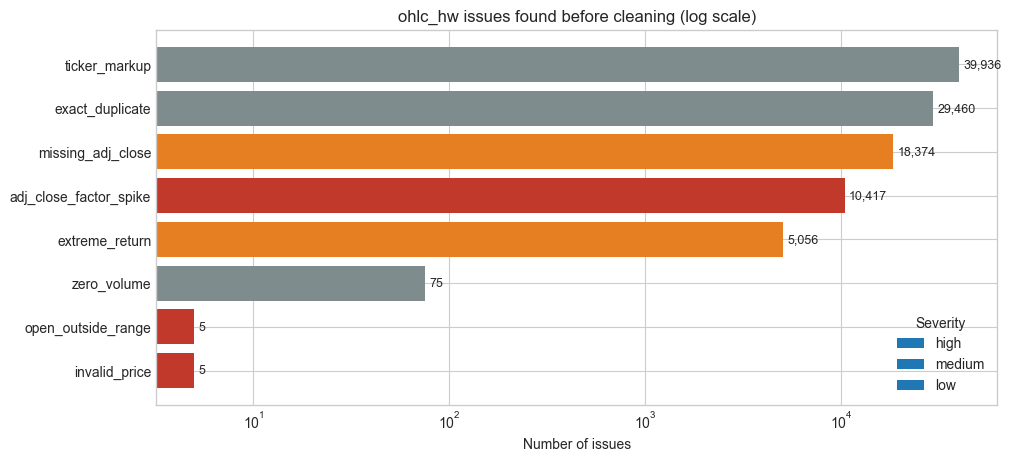

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
colors = {'high': '#c0392b', 'medium': '#e67e22', 'low': '#7f8c8d'}
plot_counts = issue_counts.sort_values('issues')
ax.barh(plot_counts['issue_type'], plot_counts['issues'], color=plot_counts['severity'].map(colors))
ax.set_xscale('log')
ax.set(title='ohlc_hw issues found before cleaning (log scale)', xlabel='Number of issues')
for severity, color in colors.items():
    ax.barh([], [], color=color, label=severity)
ax.legend(title='Severity')
for y, value in enumerate(plot_counts['issues']):
    ax.text(value * 1.05, y, f'{value:,}', va='center', fontsize=9)
plt.show()

## 1.3 Clean the data

### Repair decisions (documented)

| Problem | Decision | Reason |
|---|---|---|
| Ticker markup | Normalize (strip HTML, trim, upper-case); keep `raw_ticker` and the audit table | Must happen before grouping or de-duplicating |
| Exact duplicates | Remove extra copies | Identical information |
| Conflicting `(ticker, ts)` keys | **Quarantine** all rows of that key | No defensible way to pick one |
| All four raw prices missing | **Remove** the row *before* any filling | Nothing to repair from |
| Nonpositive / non-finite raw price | Set to missing, then treat as a missing price | An impossible value carries no information |
| Impossible OHLC relationship (open/close outside `[low, high]`) | **Option 1 with a range check**: set the bad open/close to missing, forward-fill it, and if the carried price would itself fall outside today's `[low, high]`, use today's midpoint `(high + low) / 2` instead (Option 3) | Forward fill alone can create a new violation (yesterday's close may be outside today's range). In real data we can't know which field is wrong, so the range check is re-run afterwards |
| `high < low` | **Quarantine** | We can't tell whether high or low is wrong |
| Missing raw price | Forward-fill within the ticker (carry the last known price); missing high/low are filled first and then widened to contain today's open/close; open/close use the range check above | As specified; bounds are re-checked after filling |
| **Confirmed** raw data error: an extreme return **plus** evidence that the row is wrong — either (a) the row disagrees with the reference, or (b) it is a **reverting bad tick**: a flat bar (`open = high = low = close`) with zero volume whose price is back within 5% of the previous close the next day | Interpolate O/H/L/C between valid neighbours within the ticker (`limit_area='inside'`); quarantine if at an edge. Run *after* impossible values are fixed, so they cannot inflate the standard deviation | The assignment's rule for data errors. Linear interpolation between neighbours that satisfy the bounds also satisfies them; no extrapolation. For (b) the reference contains the same bad value, so it cannot be the evidence |
| Adjustment factor for a type-(b) bad tick | Interpolate the factor between the neighbouring days' reference factors, **only if** they agree within 1% (no corporate action in between); otherwise quarantine | The reference factor on that day belongs to the bad tick (for TRV on 1976-10-28 it implies a 1.6× jump); carrying a factor across an unverified corporate action is not allowed |
| Leading gap (nothing earlier to carry) | **Quarantine** with reason `unresolved_leading_gap` | Borrowing another ticker's value or a later value would be inventing data. This is how the **5 zero-open first-day rows** are handled |
| Missing / invalid volume | Fill with 0 **and** set `volume_repaired` | Unknown volume is not evidence of no trading — the flag says so |
| Zero volume (observed) | Keep, set `zero_volume_flag` | Plausible for old/illiquid days; a review flag only |
| Missing, invalid or corrupted `adj_close`, and any row whose raw close was repaired | Rebuild `adj_close = cleaned close × reference factor`, where the factor is `ohlc.adj_close / ohlc.close` **for the same `(ticker, ts)`**; set `adj_close_repaired`; quarantine if no reference factor | Keeps one consistent adjustment convention; never forward-fills a factor across a split or dividend |
| Extreme raw return | Investigate (below) and **keep** with `extreme_return_flag` and an evidence category | A statistical outlier is not automatically an error |

The function below applies these rules in order and returns the cleaned table, the removed rows and the quarantined rows, each with a reason.

In [18]:
def clean_ohlc(raw_frame, reference, n_std=N_STD):
    """Apply the documented cleaning rules. Returns (clean, removed, quarantined).

    `raw_frame` has the ohlc_hw schema; `reference` (ohlc schema) supplies trusted
    date-specific adjustment factors and evidence for confirming raw data errors.
    """
    removed, quarantined = [], []

    def set_aside(rows, reason, bucket):
        if len(rows):
            bucket.append(rows.assign(reason=reason))

    # --- Identity: normalize labels, parse dates, de-duplicate --------------------------
    prepared = prepare_rows(raw_frame)
    bad_id = prepared['ticker'].isna() | prepared['ticker'].eq('') | prepared['ts'].isna()
    set_aside(prepared.loc[bad_id], 'missing_ticker_or_date', quarantined)
    unique_rows, exact_dups, conflicts = split_duplicates(prepared.loc[~bad_id])
    set_aside(exact_dups, 'exact_duplicate', removed)
    set_aside(conflicts, 'conflicting_duplicate_key', quarantined)

    # --- Drop rows with no raw price at all (before any filling) -------------------------
    all_missing = unique_rows[PRICE_COLS].isna().all(axis=1)
    set_aside(unique_rows.loc[all_missing], 'all_raw_prices_missing', removed)
    df = unique_rows.loc[~all_missing].sort_values(KEY).reset_index(drop=True)

    for col in ALL_PRICE_COLS + ['volume']:
        df[f'{col}_repaired'] = False
    df['repair_notes'] = ''

    def note(mask, text):
        df.loc[mask, 'repair_notes'] += text + '; '

    def quarantine(mask, reason):
        nonlocal df
        set_aside(df.loc[mask].drop(columns=[c for c in df if c.startswith('ref_')]), reason, quarantined)
        df = df.loc[~mask].reset_index(drop=True)

    df = pd.concat([df, reference_lookup(df, reference).drop(columns=KEY)], axis=1)

    # --- Invalid raw prices become missing ------------------------------------------------
    for col in PRICE_COLS:
        bad = invalid_price_mask(df, [col])[col]
        df.loc[bad, col] = np.nan
        df.loc[bad, f'{col}_repaired'] = True
        note(bad, f'{col} nonpositive/non-finite -> treated as missing')

    # --- Impossible OHLC relationships ------------------------------------------------------
    quarantine(df['high'] < df['low'], 'high_below_low')
    for col in ['open', 'close']:
        outside = (df[col] < df['low']) | (df[col] > df['high'])
        df.loc[outside, col] = np.nan
        df.loc[outside, f'{col}_repaired'] = True
        note(outside, f'{col} outside [low, high] -> treated as missing')

    # --- Fill missing high/low, then make them contain today's open/close -------------------
    for col in ['high', 'low']:
        missing = df[col].isna()
        df[col] = df.groupby('ticker')[col].ffill()
        filled = missing & df[col].notna()
        df.loc[filled, f'{col}_repaired'] = True
        note(filled, f'{col} missing -> forward-filled')
    oc_max, oc_min = df[['open', 'close']].max(axis=1), df[['open', 'close']].min(axis=1)
    raise_high, lower_low = df['high'] < oc_max, df['low'] > oc_min
    df.loc[raise_high, 'high'] = oc_max[raise_high]
    df.loc[lower_low, 'low'] = oc_min[lower_low]
    df.loc[raise_high, 'high_repaired'] = True
    df.loc[lower_low, 'low_repaired'] = True
    note(raise_high, 'filled high below open/close -> raised to max(open, close)')
    note(lower_low, 'filled low above open/close -> lowered to min(open, close)')

    # --- Fill missing open/close: carried price if inside today's range, else midpoint -------
    midpoint = (df['high'] + df['low']) / 2
    for col in ['open', 'close']:
        missing = df[col].isna()
        carried = df.groupby('ticker')[col].ffill()
        in_range = carried.between(df['low'], df['high'])
        # Midpoint only when an earlier price exists but is outside today's range; with no earlier
        # price (a leading gap) the value stays missing and the row is quarantined below.
        candidate = carried.where(in_range, midpoint).where(carried.notna())
        df.loc[missing, col] = candidate[missing]
        used_carry, used_mid = missing & in_range, missing & ~in_range & candidate.notna()
        df.loc[missing & candidate.notna(), f'{col}_repaired'] = True
        note(used_carry, f'{col} missing -> forward-filled (inside today\'s range)')
        note(used_mid, f'{col} missing; carried price outside range -> (high + low) / 2')

    # --- Confirmed raw data errors (after impossible values are fixed, so they cannot inflate
    #     the std): extreme return AND disagreement with the trusted reference ------------
    extreme, _ = flag_extreme_returns(simple_returns(df, 'close'), df['ticker'], n_std)
    disagrees = pd.concat([differs(df[c], df[f'ref_{c}']) for c in PRICE_COLS], axis=1).any(axis=1)
    bad_tick = extreme & reverting_bad_tick(df)
    df['confirmed_error'] = extreme & (disagrees | bad_tick)
    # For a bad tick the reference shares the bad value, so its factor that day can't be used:
    # interpolate between the neighbouring factors only if they agree (no corporate action between).
    by_ticker = df.groupby('ticker')['ref_factor']
    f_prev, f_next = by_ticker.shift(1), by_ticker.shift(-1)
    neighbours_agree = (f_prev / f_next - 1).abs().lt(0.01)
    df['factor_override'] = np.where(bad_tick & neighbours_agree, (f_prev + f_next) / 2, np.nan)
    note(bad_tick, 'reverting bad tick (flat zero-volume bar, price reverts next day)')
    quarantine(bad_tick & ~neighbours_agree, 'adj_factor_unverifiable')
    confirmed = df.pop('confirmed_error')
    if confirmed.any():
        df.loc[confirmed, PRICE_COLS] = np.nan
        interpolated = df.groupby('ticker')[PRICE_COLS].transform(
            lambda s: s.interpolate(limit_area='inside'))
        df.loc[confirmed, PRICE_COLS] = interpolated.loc[confirmed]
        for col in PRICE_COLS:
            df.loc[confirmed, f'{col}_repaired'] = True
        note(confirmed, 'confirmed error (extreme return, disagrees with ohlc) -> interpolated OHLC')
        quarantine(confirmed & df[PRICE_COLS].isna().any(axis=1), 'confirmed_error_at_edge')

    # --- Anything still missing has no earlier price: quarantine, never extrapolate ----------
    unresolved = df[PRICE_COLS].isna().any(axis=1)
    quarantine(unresolved, 'unresolved_leading_gap')

    # --- Volume ------------------------------------------------------------------------------
    vol = volume_issues(df)
    bad_volume = vol['missing_volume'] | vol['invalid_volume']
    df.loc[bad_volume, 'volume'] = 0
    df.loc[bad_volume, 'volume_repaired'] = True
    note(vol['missing_volume'], 'volume missing -> 0 placeholder (unknown, not zero trading)')
    note(vol['invalid_volume'], 'volume negative/non-finite -> 0 placeholder')
    df['zero_volume_flag'] = df['volume'].eq(0) & ~df['volume_repaired']
    df['volume'] = df['volume'].astype('int64')

    # --- Adjusted close: rebuild from cleaned close x trusted same-date factor ---------------
    spikes, _ = adj_factor_spikes(df)
    reasons = pd.DataFrame({
        'missing': df['adj_close'].isna(),
        'invalid': invalid_price_mask(df, ['adj_close'])['adj_close'],
        'factor_spike': spikes,
        'reference_mismatch': differs(df['adj_close'], df['ref_adj_close']),
        'raw_close_repaired': df['close_repaired'],
    })
    needs_rebuild = reasons.any(axis=1)
    factor = df['factor_override'].fillna(df['ref_factor'])
    rebuilt = df['close'] * factor
    can_rebuild = needs_rebuild & np.isfinite(rebuilt) & rebuilt.gt(0)
    df.loc[can_rebuild, 'adj_close'] = rebuilt[can_rebuild]
    df.loc[can_rebuild, 'adj_close_repaired'] = True
    for reason in reasons:
        note(can_rebuild & reasons[reason], f'adj_close {reason.replace("_", " ")} -> close x ohlc factor')
    note(can_rebuild & df['factor_override'].notna(), 'factor interpolated between neighbouring days')
    quarantine(needs_rebuild & ~can_rebuild, 'adj_close_unrepairable')

    # --- Extreme returns: keep, flag and record the evidence ---------------------------------
    df['raw_return'] = simple_returns(df, 'close')
    df['extreme_return_flag'], df['return_z'] = flag_extreme_returns(df['raw_return'], df['ticker'], n_std)
    df['extreme_return_category'] = categorize_extreme_returns(df, n_std)

    # --- Safety net: anything that still fails validation is quarantined, never saved ---------
    failing = ~row_is_valid(df)
    quarantine(failing, 'failed_post_repair_validation')

    df['any_repair'] = df[[f'{c}_repaired' for c in ALL_PRICE_COLS + ['volume']]].any(axis=1)
    df['repair_notes'] = df['repair_notes'].str.rstrip('; ')
    keep = (['ticker', 'ts'] + ALL_PRICE_COLS + ['volume', 'raw_ticker']
            + [f'{c}_repaired' for c in ALL_PRICE_COLS + ['volume']]
            + ['any_repair', 'zero_volume_flag', 'extreme_return_flag', 'extreme_return_category',
               'repair_notes'])
    clean = df[keep].reset_index(drop=True)

    def stack(parts):
        return (pd.concat(parts, ignore_index=True) if parts
                else pd.DataFrame(columns=list(prepared.columns) + ['reason']))

    return clean, stack(removed), stack(quarantined)

### Investigating extreme returns

Agreement with the reference table is weak evidence here: for the TRV bad ticks the reference has the same wrong values. So the investigation uses evidence inside each row as well:

1. **Confirmed data error** (repaired inside `clean_ohlc`, so it no longer counts as extreme afterwards): the row disagrees with the reference, or it is a **reverting bad tick** (flat zero-volume bar, price back within 5% of the previous close the next day).
2. **Corporate action**: the adjustment factor changed by more than 5% that day **and** the adjusted-close return is *not* extreme. The raw price moved because of a split or a large distribution; holders' value did not.
3. **Traded move**: the stock traded that day (volume > 0) and had a real intraday range (high > low). The price is supported by trading, so it is **kept**. *The cause (news, earnings, a market crash) is not verified here and is not claimed.*
4. **Unverified**: no trading evidence (flat bar or zero volume). Kept and flagged for manual review, because there is not enough evidence to call it an error.

In [19]:
def reverting_bad_tick(df, revert_tol=0.05):
    """Flat (O = H = L = C), zero-volume bar whose price is back near the previous close next day."""
    grouped = df.groupby('ticker')['close']
    reverts = (grouped.shift(-1) / grouped.shift(1) - 1).abs().lt(revert_tol)
    flat = df['open'].eq(df['high']) & df['high'].eq(df['low']) & df['low'].eq(df['close'])
    return flat & df['volume'].eq(0) & reverts


def categorize_extreme_returns(df, n_std=N_STD, factor_step=0.05):
    """Evidence category for each flagged extreme raw return ('' when not flagged).

    corporate_action - adjustment factor changed > factor_step and the adjusted return is not extreme
    traded_move      - the day traded (volume > 0) with an intraday range (high > low): the price
                       is supported by trading; kept, cause (news, crash, earnings) not verified
    unverified       - no trading evidence (flat bar or zero volume); kept, needs manual review
    """
    flagged = df['extreme_return_flag']
    adj_flag, _ = flag_extreme_returns(simple_returns(df, 'adj_close'), df['ticker'], n_std)
    factor = df['adj_close'] / df['close']
    factor_change = factor / factor.groupby(df['ticker']).shift(1) - 1
    corporate = flagged & factor_change.abs().gt(factor_step) & ~adj_flag
    traded = flagged & ~corporate & df['volume'].gt(0) & df['high'].gt(df['low'])
    return pd.Series(np.select([corporate, traded, flagged],
                               ['corporate_action', 'traded_move', 'unverified'], ''),
                     index=df.index)


def row_is_valid(df):
    """Row-level validity: finite positive prices, raw OHLC bounds, finite nonnegative volume."""
    prices = df[ALL_PRICE_COLS].astype(float)
    volume = df['volume'].astype(float)
    return (prices.notna().all(axis=1) & np.isfinite(prices).all(axis=1) & prices.gt(0).all(axis=1)
            & df['open'].between(df['low'], df['high']) & df['close'].between(df['low'], df['high'])
            & np.isfinite(volume) & volume.ge(0))

### Run the cleaning

In [20]:
clean, removed, quarantined = clean_ohlc(raw, reference)
print(f'Cleaned rows: {len(clean):,}')
print(f'Removed rows: {len(removed):,}')
print(removed['reason'].value_counts().to_string() if len(removed) else '  none')
print(f'Quarantined rows: {len(quarantined):,}')
print(quarantined['reason'].value_counts().to_string() if len(quarantined) else '  none')
display(quarantined[['ticker', 'ts', 'raw_ticker'] + PRICE_COLS + ['reason']])

Cleaned rows: 368,246
Removed rows: 29,460
reason
exact_duplicate    29460
Quarantined rows: 5
reason
unresolved_leading_gap    5


,ticker,ts,raw_ticker,open,high,low,close,reason
0,CVX,1962-01-02,CVX,NaN,3.30000,3.24000,3.30000,unresolved_leading_gap
1,JNJ,1962-01-02,JNJ,NaN,0.22338,0.22222,0.22338,unresolved_leading_gap
2,MCD,1966-07-05,MCD,NaN,0.27366,0.26749,0.26955,unresolved_leading_gap
3,MRK,1962-01-02,MRK,NaN,0.39703,0.39317,0.39537,unresolved_leading_gap
4,PG,1962-01-02,PG,NaN,1.44000,1.42000,1.43000,unresolved_leading_gap


As decided, the 5 first-day rows with `open = 0` are quarantined: the zero open is treated as missing, there is no earlier price to carry, so the row is an `unresolved_leading_gap`. Those tickers' cleaned histories start one trading day later.

In [21]:
repair_counts = clean[[f'{c}_repaired' for c in ALL_PRICE_COLS + ['volume']]
                      + ['zero_volume_flag', 'extreme_return_flag']].sum().rename('rows')
display(repair_counts.to_frame())
print('adj_close repair reasons (a row can have several):')
for reason in ['missing', 'factor spike', 'reference mismatch', 'raw close repaired']:
    print(f'  {reason:>20}: {clean["repair_notes"].str.contains("adj_close " + reason, regex=False).sum():,}')
bad_tick_rows = clean.loc[clean['repair_notes'].str.contains('reverting bad tick', regex=False), ['ticker', 'ts']]
print('\nReverting bad ticks repaired:', [(t, d.date().isoformat()) for t, d in bad_tick_rows.itertuples(index=False)])
print('\nExtreme-return evidence categories:')
print(clean.loc[clean['extreme_return_flag'], 'extreme_return_category'].value_counts().to_string())

,rows
open_repaired,4
high_repaired,4
low_repaired,4
close_repaired,4
adj_close_repaired,28794
volume_repaired,0
zero_volume_flag,74
extreme_return_flag,5174


adj_close repair reasons (a row can have several):
               missing: 18,374
          factor spike: 10,418
    reference mismatch: 10,417
    raw close repaired: 4



Reverting bad ticks repaired: [('AXP', '1972-12-14'), ('TRV', '1976-10-28'), ('TRV', '1978-12-20'), ('TRV', '1981-08-10')]

Extreme-return evidence categories:
extreme_return_category
traded_move         4918
unverified           252
corporate_action       4


In [22]:
returns_view = clean.assign(raw_return_pct=simple_returns(clean, 'close') * 100,
                            adj_return_pct=simple_returns(clean, 'adj_close') * 100)
view_cols = ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'raw_return_pct', 'adj_return_pct']
bad_ticks = clean['repair_notes'].str.contains('reverting bad tick', regex=False)
print(f'Confirmed reverting bad ticks repaired: {bad_ticks.sum()}')
for i in clean.index[bad_ticks]:
    ticker, day = clean.loc[i, 'ticker'], clean.loc[i, 'ts']
    print(f'{ticker} {day.date()}: neighbouring days, before vs after cleaning')
    near = diag.loc[(diag['ticker'] == ticker) & diag['ts'].between(day - pd.Timedelta(days=4), day + pd.Timedelta(days=4)),
                    ['ticker', 'ts', 'close', 'adj_close', 'volume']]
    display(near.merge(clean[['ticker', 'ts', 'close', 'adj_close']], on=KEY, suffixes=('_before', '_after')))
flagged_view = returns_view.loc[returns_view['extreme_return_flag']]
print('Corporate actions (raw and adjusted returns disagree because the adjustment factor changed):')
display(flagged_view.loc[flagged_view['extreme_return_category'] == 'corporate_action', view_cols]
        .sort_values('raw_return_pct').head(8))
print('Largest kept traded moves (cause not claimed):')
display(flagged_view.loc[flagged_view['extreme_return_category'] == 'traded_move', view_cols]
        .sort_values('raw_return_pct', key=abs, ascending=False).head(8))
print('Unverified flags (no trading evidence), largest first:')
display(flagged_view.loc[flagged_view['extreme_return_category'] == 'unverified', view_cols]
        .sort_values('raw_return_pct', key=abs, ascending=False).head(8))

Confirmed reverting bad ticks repaired: 4
AXP 1972-12-14: neighbouring days, before vs after cleaning


,ticker,ts,close_before,adj_close_before,volume,close_after,adj_close_after
0,AXP,1972-12-11,4.66,1.57,624786,4.660,1.570000
1,AXP,1972-12-12,4.63,1.56,672324,4.630,1.560000
2,AXP,1972-12-13,4.59,NaN,844816,4.590,1.550000
3,AXP,1972-12-14,4.01,1.35,0,4.595,1.554996
4,AXP,1972-12-15,4.60,1.56,979282,4.600,1.560000
5,AXP,1972-12-18,4.60,1.56,421049,4.600,1.560000


TRV 1976-10-28: neighbouring days, before vs after cleaning


,ticker,ts,close_before,adj_close_before,volume,close_after,adj_close_after
0,TRV,1976-10-25,4.52,0.96051,29600,4.52,0.960510
1,TRV,1976-10-26,4.50,0.95719,91200,4.50,0.957190
2,TRV,1976-10-27,4.61,13.88325,230400,4.61,0.980460
3,TRV,1976-10-28,9.22,NaN,0,4.65,0.988767
4,TRV,1976-10-29,4.69,0.99707,79200,4.69,0.997070
5,TRV,1976-11-01,4.66,0.99043,59200,4.66,0.990430


TRV 1978-12-20: neighbouring days, before vs after cleaning


...

,ticker,ts,open,high,low,close,adj_close,volume,raw_return_pct,adj_return_pct
264444,MSFT,2004-11-15,27.36000,27.50000,27.20000,27.39000,19.05000,104734064,-8.608609,1.871658
106253,DIS,1975-03-02,0.82144,0.87863,0.81884,0.87863,0.54542,6097362,8.230990,1.281289
106273,DIS,1975-03-25,0.91502,0.95141,0.91502,0.93581,0.58092,4635534,8.736725,1.756906
105957,DIS,1974-01-20,0.84483,0.92542,0.80584,0.91502,0.56801,2962125,9.592421,2.556649


Largest kept traded moves (cause not claimed):


,ticker,ts,open,high,low,close,adj_close,volume,raw_return_pct,adj_return_pct
4999,AAPL,2000-09-29,0.503350,0.51786,0.453130,0.459820,0.388310,3128875900,-51.869452,-51.868562
280841,NVDA,2000-03-07,0.156250,0.18177,0.149480,0.173570,0.159200,1952246199,42.410568,42.422616
281950,NVDA,2004-08-06,0.084917,0.08500,0.077500,0.078584,0.072076,5092064120,-35.231435,-35.235780
336475,UNH,2008-10-13,18.060000,23.52000,17.830000,23.380000,18.730000,17691904,34.755043,34.748201
22610,AMZN,2001-11-26,0.491500,0.61100,0.490000,0.610500,0.610500,1013784000,34.471366,34.471366
331184,UNH,1987-10-20,0.140630,0.14063,0.089844,0.097656,0.077355,2646400,-34.211803,-34.210997
22454,AMZN,2001-04-09,0.592000,0.59500,0.535000,0.559000,0.559000,468114000,33.572282,33.572282
4204,AAPL,1997-08-06,0.176900,0.24777,0.176900,0.234930,0.198400,4192008288,33.225587,33.234840


Unverified flags (no trading evidence), largest first:


,ticker,ts,open,high,low,close,adj_close,volume,raw_return_pct,adj_return_pct
213785,MCD,1968-01-02,0.174900,0.174900,0.174900,0.174900,0.075921,6755143,-75.362033,-75.588106
317762,TRV,1974-08-05,2.630000,2.630000,2.630000,2.630000,0.558360,232800,16.888889,16.665274
125344,HD,1982-03-19,0.065846,0.065846,0.065846,0.065846,0.037870,820125,15.385694,15.385701
125241,HD,1981-10-21,0.043898,0.043898,0.043898,0.043898,0.025247,7107750,15.384413,15.384411
330637,UNH,1985-08-21,0.332030,0.332030,0.332030,0.332030,0.263010,1056000,14.865426,14.866576
29250,AXP,1975-08-05,2.750000,2.750000,2.750000,2.750000,0.930200,915008,14.583333,15.230722
11113,AMGN,1983-09-16,0.161460,0.161460,0.161460,0.161460,0.114450,1680016,-13.888000,-13.889098
330627,UNH,1985-08-07,0.304690,0.304690,0.304690,0.304690,0.241350,1219200,-13.332006,-13.333094


**How to read this:**

- **4 reverting bad ticks** were confirmed and interpolated, and so was each one's adjustment factor: the 3 TRV days, plus **AXP on 1972-12-14** (a flat, zero-volume close of 4.01 between 4.59 and 4.60). The +100% / −50% TRV return pairs are gone.
- **Corporate actions** are few, because the raw closes are already split-adjusted. Example: MSFT on 2004-11-15 shows a raw −8.6% but an adjusted +1.9%. That fits a large special dividend (Microsoft paid one in November 2004), not a loss for shareholders. The DIS rows from 1974–75 match the same mechanical rule without an obvious event, so this label means "explained by the adjustment factor", not "verified event".
- **Traded moves** are kept. They include market-wide days such as 19–20 October 1987, September 2008 and March 2020, and company events such as AAPL on 2000-09-29. These are flagged for review, but nothing here proves an error.
- **Unverified** flags are mostly flat or zero-volume bars in very old data. One example is MCD on 1968-01-02: a lasting −75% level shift that `adj_close` also shows, perhaps an unadjusted corporate action. There is no evidence that would justify repairing these rows, so they are kept and flagged with this stated uncertainty.

The disagreement-with-reference path of the interpolation repair is exercised in Section 4.

### Before and after: adjusted close

The corrupted `adj_close` spikes are obvious on a log-scale chart; after the rebuild the series is continuous.

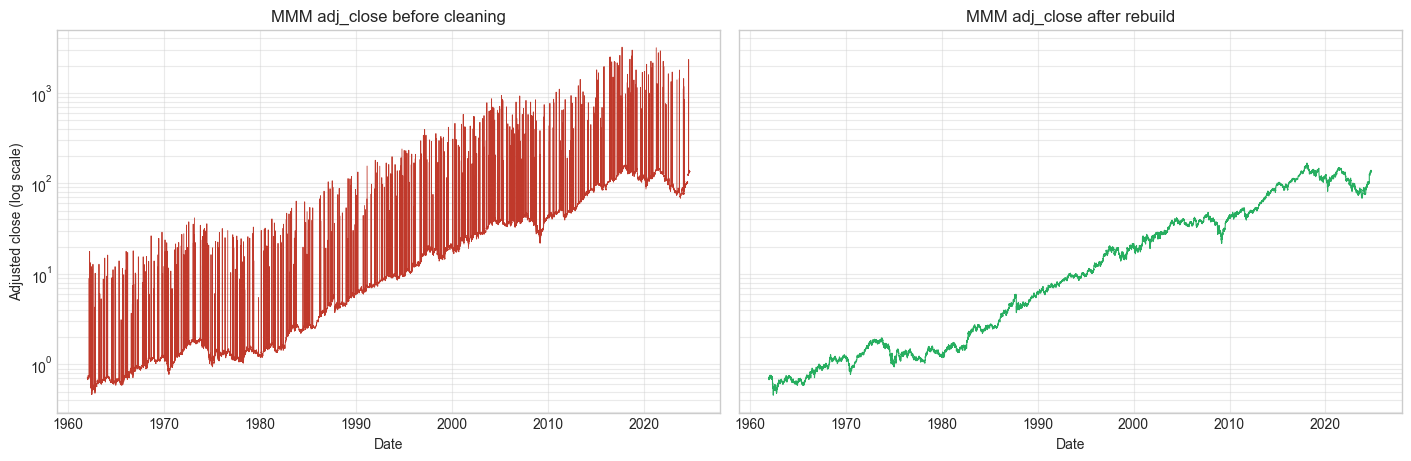

In [23]:
worst_ticker = diag.loc[diag['adj_spike'], 'ticker'].value_counts().idxmax()
before = diag.loc[diag['ticker'] == worst_ticker]
after = clean.loc[clean['ticker'] == worst_ticker]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True, layout='constrained')
axes[0].plot(before['ts'], before['adj_close'], color='#c0392b', linewidth=0.6)
axes[0].set(title=f'{worst_ticker} adj_close before cleaning', ylabel='Adjusted close (log scale)')
axes[1].plot(after['ts'], after['adj_close'], color='#27ae60', linewidth=0.8)
axes[1].set(title=f'{worst_ticker} adj_close after rebuild')
for ax in axes:
    ax.set_yscale('log'); ax.set_xlabel('Date'); ax.grid(True, which='both', alpha=0.4)
plt.show()

## Validation

The cleaned data must have:

- no missing, non-finite or nonpositive values in raw **and** adjusted price columns;
- unique `(ticker, ts)` keys;
- finite, nonnegative volume;
- valid raw price relationships (`low <= open <= high`, `low <= close <= high`, `high >= low`);
- no remaining adjustment-factor spikes (adjusted-price consistency).

`validate_clean` is run on the frame and again on the table read back from the database, so it also checks the saved `ts` format.

In [24]:
def validate_clean(frame):
    """Return a Series of named Boolean checks for a cleaned OHLC table."""
    prices = frame[ALL_PRICE_COLS].astype(float)
    volume = frame['volume'].astype(float)
    ts_text = frame['ts'] if frame['ts'].dtype == object else frame['ts'].dt.strftime('%Y-%m-%d')
    ordered = frame.assign(ts=pd.to_datetime(frame['ts'])).sort_values(KEY).reset_index(drop=True)
    return pd.Series({
        'no missing prices (raw + adjusted)': bool(prices.notna().all().all()),
        'all prices finite': bool(np.isfinite(prices).all().all()),
        'all prices positive': bool(prices.gt(0).all().all()),
        'unique (ticker, ts) keys': bool(not frame.duplicated(KEY).any()),
        'volume finite and nonnegative': bool(np.isfinite(volume).all() and volume.ge(0).all()),
        'low <= open <= high': bool(frame['open'].between(frame['low'], frame['high']).all()),
        'low <= close <= high': bool(frame['close'].between(frame['low'], frame['high']).all()),
        'high >= low': bool(frame['high'].ge(frame['low']).all()),
        'no adjustment-factor spikes': bool(not adj_factor_spikes(ordered)[0].any()),
        'ts is ISO YYYY-MM-DD': bool(ts_text.str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()),
    }, name='passed')


checks = validate_clean(clean)
display(checks.to_frame())
assert checks.all(), checks[~checks]

,passed
no missing prices (raw + adjusted),True
all prices finite,True
all prices positive,True
"unique (ticker, ts) keys",True
volume finite and nonnegative,True
low <= open <= high,True
low <= close <= high,True
high >= low,True
no adjustment-factor spikes,True
ts is ISO YYYY-MM-DD,True


### Row accounting

Every raw row is either retained, removed (exact duplicate / no prices at all) or quarantined with a reason.

In [25]:
accounting = pd.Series({
    'raw ohlc_hw rows': len(raw),
    'removed: exact duplicates': int((removed['reason'] == 'exact_duplicate').sum()) if len(removed) else 0,
    'removed: all raw prices missing': int((removed['reason'] == 'all_raw_prices_missing').sum()) if len(removed) else 0,
    'quarantined': len(quarantined),
    'retained in ohlc_hw_cleaned': len(clean),
}, name='rows')
display(accounting.to_frame())
assert accounting.iloc[0] == accounting.iloc[1:].sum(), 'Every raw row must be accounted for.'

,rows
raw ohlc_hw rows,397711
removed: exact duplicates,29460
removed: all raw prices missing,0
quarantined,5
retained in ohlc_hw_cleaned,368246


### Save to the database

Written to the **working copy** `data/data.db`:

| Table | Contents |
|---|---|
| `ohlc_hw_cleaned` | Cleaned data with repair flags, `repair_notes`, review flags and the original `raw_ticker` label; `ts` stored as `YYYY-MM-DD` |
| `ohlc_hw_quarantine` | Rows set aside, with a `reason` |
| `ohlc_hw_quality_report` | The pre-repair Data Quality Report |
| `ohlc_hw_ticker_audit` | Every raw label and the ticker it was normalized to |

`if_exists='replace'` only replaces these output tables; the raw `ohlc_hw` table is untouched (checked below).

In [26]:
def to_sql_frame(frame):
    """Copy with ISO date strings and integer flags, ready for SQLite."""
    out = frame.copy()
    for col in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[col]):
            out[col] = out[col].dt.strftime('%Y-%m-%d')
        elif pd.api.types.is_bool_dtype(out[col]):
            out[col] = out[col].astype(int)
        elif pd.api.types.is_string_dtype(out[col]):
            out[col] = out[col].astype(object)
    return out


with closing(sqlite3.connect(WORK_DB)) as conn:
    to_sql_frame(clean).to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
    to_sql_frame(quarantined).to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)
    to_sql_frame(quality_report).to_sql('ohlc_hw_quality_report', conn, if_exists='replace', index=False)
    to_sql_frame(ticker_audit).to_sql('ohlc_hw_ticker_audit', conn, if_exists='replace', index=False)
    conn.execute('CREATE UNIQUE INDEX IF NOT EXISTS idx_ohlc_hw_cleaned_key ON ohlc_hw_cleaned (ticker, ts)')
    conn.commit()
    saved = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', conn)
    raw_after = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)

print(f'Saved ohlc_hw_cleaned: {len(saved):,} rows, {saved["ticker"].nunique()} tickers')
saved_checks = validate_clean(saved)
display(saved_checks.to_frame('passed after reload'))
assert saved_checks.all()
pd.testing.assert_frame_equal(raw_after, raw)
print('Raw ohlc_hw table is unchanged.')

Saved ohlc_hw_cleaned: 368,246 rows, 30 tickers


,passed after reload
no missing prices (raw + adjusted),True
all prices finite,True
all prices positive,True
"unique (ticker, ts) keys",True
volume finite and nonnegative,True
low <= open <= high,True
low <= close <= high,True
high >= low,True
no adjustment-factor spikes,True
ts is ISO YYYY-MM-DD,True


Raw ohlc_hw table is unchanged.


### Re-run the detectors on the cleaned data

The same detectors, applied after cleaning: every high-severity issue is gone. What remains are **review flags** that were deliberately kept (extreme returns, zero-volume days).

In [27]:
after_diag = clean.copy()
after_diag['raw_return'] = simple_returns(after_diag, 'close')
after_diag['extreme_return'], after_diag['return_z'] = flag_extreme_returns(after_diag['raw_return'], after_diag['ticker'])
after_diag['adj_spike'], after_diag['adj_factor'] = adj_factor_spikes(after_diag)
_, after_gaps = find_missing_trading_days(after_diag, calendar)
empty = prepared.iloc[0:0]
after_report = build_quality_report(after_diag.assign(raw_ticker=after_diag['ticker']), after_diag,
                                    empty, empty, after_gaps)
comparison = pd.DataFrame({
    'before': quality_report.groupby('issue_type').size(),
    'after': after_report.groupby('issue_type').size(),
}).fillna(0).astype(int)
display(comparison)
print('Missing trading days after cleaning (the quarantined first-day rows):')
display(after_gaps)

,before,after
issue_type,,
adj_close_factor_spike,10417,0
exact_duplicate,29460,0
extreme_return,5056,5174
invalid_price,5,0
missing_adj_close,18374,0
missing_trading_day,0,5
open_outside_range,5,0
ticker_markup,39936,0
zero_volume,75,74


Missing trading days after cleaning (the quarantined first-day rows):


,ticker,issue_date
0,CVX,1962-01-02
1,JNJ,1962-01-02
2,MCD,1966-07-05
3,MRK,1962-01-02
4,PG,1962-01-02


- The **5 missing trading days** after cleaning are exactly the quarantined first-day rows: removing them shortens those histories by one day. This is disclosed rather than filled.
- `extreme_return` **rises**, almost entirely in TRV: 87 flags before cleaning, 206 after. This is a **masking effect**. TRV's three ±100% bad ticks inflated its standard deviation so much that 119 genuine large moves stayed below the 3σ line; once the bad ticks are repaired, those moves are flagged. It shows why a full-history 3σ screen cannot be the only check, and why the screen is re-run after repairs. (AXP loses 2 flags with its bad tick; MCD gains 1 because its quarantined first row shifts which return comes first.)

### Before / after statistics

In [28]:
stats_cols = ALL_PRICE_COLS + ['volume']
before_after = pd.concat({'before (raw ohlc_hw)': raw[stats_cols].describe().T,
                          'after (ohlc_hw_cleaned)': clean[stats_cols].describe().T}, axis=0)
display(before_after.round(4))
summary_table = pd.DataFrame({
    'rows': [len(raw), len(clean)],
    'distinct ticker labels': [raw['ticker'].nunique(), clean['ticker'].nunique()],
    'missing adj_close': [raw['adj_close'].isna().sum(), clean['adj_close'].isna().sum()],
    'max adj_close': [raw['adj_close'].max(), clean['adj_close'].max()],
    'nonpositive prices': [int((raw[ALL_PRICE_COLS] <= 0).sum().sum()), int((clean[ALL_PRICE_COLS] <= 0).sum().sum())],
    'duplicate (ticker, ts)': [int(prepared.duplicated(KEY).sum()), int(clean.duplicated(KEY).sum())],
}, index=['before', 'after']).T
display(summary_table)

count          mean           std     min           25%         50%           75%           max
before (raw ohlc_hw)    open       397711.0  4.628550e+01  6.713260e+01  0.0000  4.209900e+00       19.85  5.753000e+01  6.042600e+02
                        high       397711.0  4.674770e+01  6.777820e+01  0.0052  4.240000e+00       20.06  5.813000e+01  6.086300e+02
                        low        397711.0  4.581630e+01  6.647720e+01  0.0048  4.160000e+00       19.63  5.695000e+01  5.978800e+02
                        close      397711.0  4.629290e+01  6.714190e+01  0.0052  4.200000e+00       19.86  5.753000e+01  6.054000e+02
                        adj_close  377856.0  5.165230e+01  1.945840e+02  0.0029  1.390000e+00       11.96  4.377000e+01  1.044251e+04
                        volume     397711.0  3.097773e+07  1.266237e+08  0.0000  1.730700e+06  4648200.00  1.102380e+07  9.276606e+09
after (ohlc_hw_cleaned) open       368246.0  4.630940e+01  6.714330e+01  0.0052  4.210000e+00       19.89  5.756000e+01  6.042600e+02
                        high       368246.0  4.677180e+01  6.778930e+01  0.0052  4.250000e+00       20.09  5.816000e+01  6.086300e+02
                        low        368246.0  4.584030e+01  6.648950e+01  0.0048  4.170000e+00       19.67  5.699750e+01  5.978800e+02
                        close      368246.0  4.631730e+01  6.715500e+01  0.0052  4.210000e+00       19.91  5.757000e+01  6.054000e+02
                        adj_close  368246.0  3.727470e+01  6.358790e+01  0.0029  1.310000e+00       11.46  4.157000e+01  6.054000e+02
                        volume     368246.0  3.095184e+07  1.266153e+08  0.0000  1.731514e+06  4649648.00  1.102160e+07  9.276606e+09

,before,after
rows,397711.000000,368246.0
distinct ticker labels,150.000000,30.0
missing adj_close,19855.000000,0.0
max adj_close,10442.510783,605.4
nonpositive prices,5.000000,0.0
"duplicate (ticker, ts)",29460.000000,0.0


## 4. Injected examples for cases absent from the real data

The real `ohlc_hw` has no missing raw prices, no all-missing rows, no `high < close` rows, no missing volume, no conflicting keys, no confirmed raw data errors and no missing trading days. The assignment asks us to show that the detectors and repairs still work for those cases, so we build a small dirty table with known faults and a matching clean reference, then run **the same functions** used above.

`make_demo_prices` builds 40 sessions of a smooth synthetic stock `DEMO` plus a short second stock `DEMO2`. The reference uses an adjustment factor of 0.9 that steps to 1.0 on day 30 (a dividend-like step that must *not* be flagged as a spike).

In [29]:
def make_demo_prices(n=40, seed=7):
    """Synthetic clean reference table (ohlc schema) for two demo tickers."""
    rng = np.random.default_rng(seed)
    rows = []
    for ticker, start, days in [('DEMO', 100.0, n), ('DEMO2', 50.0, 8)]:
        dates = pd.bdate_range('2024-01-02', periods=days)
        close = start * np.exp(np.cumsum(rng.normal(0, 0.01, days)))
        open_ = close * np.exp(rng.normal(0, 0.003, days))
        high = np.maximum(open_, close) * (1 + np.abs(rng.normal(0, 0.004, days)))
        low = np.minimum(open_, close) * (1 - np.abs(rng.normal(0, 0.004, days)))
        factor = np.where(np.arange(days) < 30, 0.9, 1.0)
        rows.append(pd.DataFrame({'ts': dates.strftime('%Y-%m-%d'), 'open': open_, 'high': high,
                                  'low': low, 'close': close, 'adj_close': close * factor,
                                  'volume': rng.integers(1_000, 5_000, days), 'ticker': ticker}))
    return pd.concat(rows, ignore_index=True)


demo_ref = make_demo_prices()
demo_raw = demo_ref.copy()  # row positions 0-39 are DEMO, 40-47 are DEMO2
demo_raw['volume'] = demo_raw['volume'].astype(float)
faults = {
    1:  'label "<b>demo</b>" (markup)',
    2:  'label " Demo " (whitespace/case)',
    3:  'exact duplicate added',
    5:  'row deleted (missing trading day)',
    8:  'close missing',
    12: 'all four raw prices missing',
    15: 'close x 1.5 (high < close)',
    18: 'volume missing',
    20: 'adj_close missing',
    22: 'adj_close x 10 (corrupted)',
    25: 'whole bar x 1.3 (confirmed error: extreme return, disagrees with reference)',
    28: 'volume = 0 (observed zero)',
    40: 'DEMO2 first day: open = 0 (leading gap)',
    44: 'DEMO2 conflicting duplicate (same key, different close)',
}
demo_raw.loc[1, 'ticker'] = '<b>demo</b>'
demo_raw.loc[2, 'ticker'] = ' Demo '
demo_raw.loc[8, 'close'] = np.nan
demo_raw.loc[12, PRICE_COLS] = np.nan
demo_raw.loc[15, 'close'] *= 1.5
demo_raw.loc[18, 'volume'] = np.nan
demo_raw.loc[20, 'adj_close'] = np.nan
demo_raw.loc[22, 'adj_close'] *= 10
demo_raw.loc[25, PRICE_COLS] *= 1.3
demo_raw.loc[28, 'volume'] = 0
demo_raw.loc[40, 'open'] = 0.0
conflict_row = demo_raw.loc[[44]].assign(close=lambda t: t['close'] * 1.02)
demo_raw = pd.concat([demo_raw.drop(index=5), demo_raw.loc[[3]], conflict_row], ignore_index=True)
display(pd.Series(faults, name='injected fault').to_frame())

,injected fault
1,"label ""<b>demo</b>"" (markup)"
2,"label "" Demo "" (whitespace/case)"
3,exact duplicate added
5,row deleted (missing trading day)
8,close missing
12,all four raw prices missing
15,close x 1.5 (high < close)
18,volume missing
20,adj_close missing
22,adj_close x 10 (corrupted)


**Detection on the injected table** (same detectors, pre-repair):

In [30]:
demo_prepared = prepare_rows(demo_raw)
demo_unique, demo_dups, demo_conflicts = split_duplicates(demo_prepared)
demo_diag = demo_unique.sort_values(KEY).reset_index(drop=True)
demo_diag['raw_return'] = simple_returns(demo_diag, 'close')
demo_diag['extreme_return'], demo_diag['return_z'] = flag_extreme_returns(demo_diag['raw_return'], demo_diag['ticker'])
demo_diag['adj_spike'], demo_diag['adj_factor'] = adj_factor_spikes(demo_diag)
demo_calendar = demo_ref[['ticker', 'ts']].assign(ts=lambda t: pd.to_datetime(t['ts']))
demo_gap_summary, demo_gap_issues = find_missing_trading_days(demo_diag, demo_calendar)
for row in demo_gap_summary.itertuples():
    print(f'Ticker {row.ticker} is missing {row.missing_days} trading days between {row.start} and {row.end}')
demo_report = build_quality_report(demo_prepared, demo_diag, demo_dups, demo_conflicts, demo_gap_issues)
display(demo_report)

Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-02-26
Ticker DEMO2 is missing 1 trading days between 2024-01-02 and 2024-01-11


,ticker,issue_type,issue_date,description,severity
0,DEMO,ticker_markup,2024-01-03,Vendor label contained markup/whitespace/case; normalized to DEMO,low
1,DEMO,ticker_markup,2024-01-04,Vendor label contained markup/whitespace/case; normalized to DEMO,low
2,DEMO,exact_duplicate,2024-01-05,Exact duplicate of another record; extra copy removed,low
3,DEMO,missing_trading_day,2024-01-09,Date in reference calendar but absent from ohlc_hw,medium
4,DEMO,missing_price,2024-01-12,Missing raw price(s): close,high
5,DEMO,missing_price,2024-01-18,"Missing raw price(s): open, high, low, close",high
6,DEMO,extreme_return,2024-01-23,"Raw close return +51.05% (z = +4.0); review: split, news or error?",medium
7,DEMO,high_below_close,2024-01-23,high 99.11 < close 148,high
8,DEMO,missing_volume,2024-01-26,Volume missing,medium
9,DEMO,missing_adj_close,2024-01-30,adj_close missing; raw close available,medium


In [31]:
found = set(demo_report['issue_type'])
expected_issues = {'ticker_markup', 'exact_duplicate', 'conflicting_key', 'missing_trading_day',
                   'missing_price', 'high_below_close', 'missing_volume', 'missing_adj_close',
                   'adj_close_factor_spike', 'extreme_return', 'invalid_price', 'open_outside_range',
                   'zero_volume'}
assert expected_issues <= found, expected_issues - found
demo_gaps_by_ticker = demo_gap_issues.groupby('ticker')['issue_date'].apply(list)
assert demo_gaps_by_ticker['DEMO'] == [pd.Timestamp(demo_ref.loc[5, 'ts'])]
# DEMO2's conflicting key is held out of the diagnosis table, so that date also shows as absent.
assert demo_gaps_by_ticker['DEMO2'] == [pd.Timestamp(demo_ref.loc[44, 'ts'])]
step_day = pd.Timestamp(demo_ref.loc[30, 'ts'])
assert not demo_diag.loc[demo_diag['ts'] == step_day, 'adj_spike'].any(), 'A factor step is not a spike.'
print('Every injected fault was detected; the legitimate factor step on day 30 was not flagged.')

Every injected fault was detected; the legitimate factor step on day 30 was not flagged.


**Repair on the injected table**, then the same validation:

In [32]:
demo_clean, demo_removed, demo_quarantined = clean_ohlc(demo_raw, demo_ref)
print('Removed:'); display(demo_removed[['ticker', 'ts', 'close', 'reason']])
print('Quarantined:'); display(demo_quarantined[['ticker', 'ts', 'open', 'close', 'reason']])
show = demo_clean['any_repair'] | demo_clean['zero_volume_flag']
display(demo_clean.loc[show, ['ticker', 'ts'] + PRICE_COLS + ['adj_close', 'volume', 'repair_notes']])
demo_checks = validate_clean(demo_clean)
display(demo_checks.to_frame())
assert demo_checks.all()

Removed:


,ticker,ts,close,reason
0,DEMO,2024-01-05,99.138974,exact_duplicate
1,DEMO,2024-01-18,NaN,all_raw_prices_missing


Quarantined:


,ticker,ts,open,close,reason
0,DEMO2,2024-01-08,49.81543,49.673728,conflicting_duplicate_key
1,DEMO2,2024-01-08,49.81543,50.667203,conflicting_duplicate_key
2,DEMO2,2024-01-02,NaN,49.983108,unresolved_leading_gap


,ticker,ts,open,high,low,close,adj_close,volume,repair_notes
7,DEMO,2024-01-12,98.417298,99.066829,97.729914,98.398371,88.558534,1692,close missing; carried price outside range -> (high + low) / 2; adj_close ra...
13,DEMO,2024-01-23,98.875575,99.106304,98.104182,98.605243,88.744719,4845,"close outside [low, high] -> treated as missing; close missing; carried pric..."
16,DEMO,2024-01-26,95.497355,96.142231,95.025313,95.086118,85.577506,0,"volume missing -> 0 placeholder (unknown, not zero trading)"
18,DEMO,2024-01-30,92.211022,92.323327,91.749884,92.154845,82.939360,2648,adj_close missing -> close x ohlc factor
20,DEMO,2024-02-01,90.815201,90.874795,90.761946,90.780534,81.702481,1361,adj_close factor spike -> close x ohlc factor; adj_close reference mismatch ...
23,DEMO,2024-02-06,89.994597,90.261959,89.537744,89.953957,80.958561,1247,"confirmed error (extreme return, disagrees with ohlc) -> interpolated OHLC; ..."
26,DEMO,2024-02-09,87.868871,88.280705,87.529374,88.218456,79.396610,0,


,passed
no missing prices (raw + adjusted),True
all prices finite,True
all prices positive,True
"unique (ticker, ts) keys",True
volume finite and nonnegative,True
low <= open <= high,True
low <= close <= high,True
high >= low,True
no adjustment-factor spikes,True
ts is ISO YYYY-MM-DD,True


In [33]:
ref_idx = demo_ref.assign(ts=pd.to_datetime(demo_ref['ts'])).set_index(KEY)
out = demo_clean.set_index(KEY)
day = lambda i: (demo_ref.loc[i, 'ticker'], pd.Timestamp(demo_ref.loc[i, 'ts']))

# Missing close (row 8): previous close if it lies inside today's range, otherwise the midpoint.
prev_close, (lo, hi) = ref_idx.loc[day(7), 'close'], ref_idx.loc[day(8), ['low', 'high']]
expected_fill = prev_close if lo <= prev_close <= hi else (lo + hi) / 2
print('Row 8 close filled with', 'the previous close' if lo <= prev_close <= hi else 'the high-low midpoint')
assert np.isclose(out.loc[day(8), 'close'], expected_fill)
# All-missing row (12) was removed before filling, not filled.
assert day(12) not in out.index and (demo_removed['reason'] == 'all_raw_prices_missing').sum() == 1
# high < close (row 15): the bad close is replaced and the row is inside its range again.
assert out.loc[day(15), 'low'] <= out.loc[day(15), 'close'] <= out.loc[day(15), 'high']
# Missing volume (row 18): 0 placeholder with a repair flag; observed zero (row 28) is only flagged.
assert out.loc[day(18), 'volume'] == 0 and out.loc[day(18), 'volume_repaired']
assert out.loc[day(28), 'zero_volume_flag'] and not out.loc[day(28), 'volume_repaired']
# adj_close missing (20) / corrupted (22): rebuilt from close x reference factor.
for i in [20, 22]:
    assert np.isclose(out.loc[day(i), 'adj_close'], ref_idx.loc[day(i), 'adj_close'])
    assert out.loc[day(i), 'adj_close_repaired']
# Confirmed error (25): interpolated between the neighbouring valid bars.
expected_close = (ref_idx.loc[day(24), 'close'] + ref_idx.loc[day(26), 'close']) / 2
assert np.isclose(out.loc[day(25), 'close'], expected_close)
# DEMO2: zero open on the first day -> leading gap quarantined; conflicting key quarantined (2 rows).
assert set(demo_quarantined['reason']) >= {'unresolved_leading_gap', 'conflicting_duplicate_key'}
assert (demo_quarantined['reason'] == 'conflicting_duplicate_key').sum() == 2
# Exact duplicate removed; every row accounted for.
assert len(demo_raw) == len(demo_clean) + len(demo_removed) + len(demo_quarantined)
print('All injected repairs behaved as documented.')

Row 8 close filled with the high-low midpoint
All injected repairs behaved as documented.


## Summary

- **Ticker labels:** 150 vendor labels (HTML-wrapped variants) normalized to 30 tickers; the audit is saved.
- **Duplicates:** 29,460 exact duplicates removed; no conflicting keys.
- **Missing data:** only `adj_close` (18,374 cells after de-duplication); no missing trading days against the per-ticker `ohlc` calendar.
- **Corrupted adjusted closes:** 10,417 values 4–24× too large, found by an adjustment-factor spike detector that uses only the dirty table and agrees exactly with the reference. All missing and corrupted adjusted closes were rebuilt as `close × ohlc factor` for the same date and flagged.
- **Invalid prices:** 5 first-day rows with `open = 0` quarantined as unresolved leading gaps.
- **Zero volume:** 75 old (1962–1982) days kept and flagged.
- **Extreme returns:** 4 reverting bad ticks (3 TRV days with flat, zero-volume bars at 2× the neighbours; 1 AXP day) were confirmed as errors and interpolated, along with their adjustment factors. Repairing them revealed 119 TRV moves that the bad ticks had masked. Every other extreme return is kept and flagged with an evidence category (corporate action / traded move / unverified); no cause is claimed without evidence.
- **Validation:** all checks pass on the saved `ohlc_hw_cleaned` table; the raw table is unchanged; every raw row is accounted for.

Next: `02_stock_report_template.ipynb` reads `ohlc_hw_cleaned`.